# Bootstrap Consensus Tree

Uses the `bdi` package's `eder_bct` and `plot_bct` functions
with networkx and matplotlib visualization.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from bdi import eder_bct, plot_bct
from bdi.metrics import cosine

import matplotlib as mpl

mpl.rcParams["figure.dpi"] = 600

## Load and Prepare Data

In [5]:
vecs = pd.read_csv("output.csv", encoding="utf-8")

if "LEN" in vecs.columns:
    corpus = vecs[vecs.LEN >= 20].copy()
else:
    corpus = vecs.copy()

meta_cols = ["Author", "Work", "Poem"]
feature_cols = [c for c in corpus.columns if c not in meta_cols]

ss = StandardScaler()
X = pd.DataFrame(
    ss.fit_transform(corpus[feature_cols]), columns=feature_cols, index=corpus.index
)

# Node labels with chunk numbers
y = list(corpus.Poem)

# Derive work names (strip chunk numbers) for coloring
import re

work_names = [re.sub(r"\s*-\s*\d+$", "", p) for p in y]

print(f"BCT input: {X.shape[0]} nodes, {X.shape[1]} features")
print(f"Unique works: {len(set(work_names))}")

BCT input: 663 nodes, 21 features
Unique works: 47


## Run BCT

In [7]:
graph_trim = eder_bct(
    X,
    y,
    n=1000,
    keep_pct=0.2,
    feats_pct=0.35,
    rng=np.random.default_rng(seed=42),
    metric=cosine,
)
print(f"Graph edges: {len(graph_trim)}")
graph_trim.head()

Graph edges: 25021


,from,to,weight
123134,victoris - 3,victoris - 2,2746
123007,victoris - 2,victoris - 3,2618
30738,contemptu - 4,contemptu - 16,2405
30637,contemptu - 16,contemptu - 4,2389
36530,dialogi - 42,dialogi - 33,2098


## Visualize

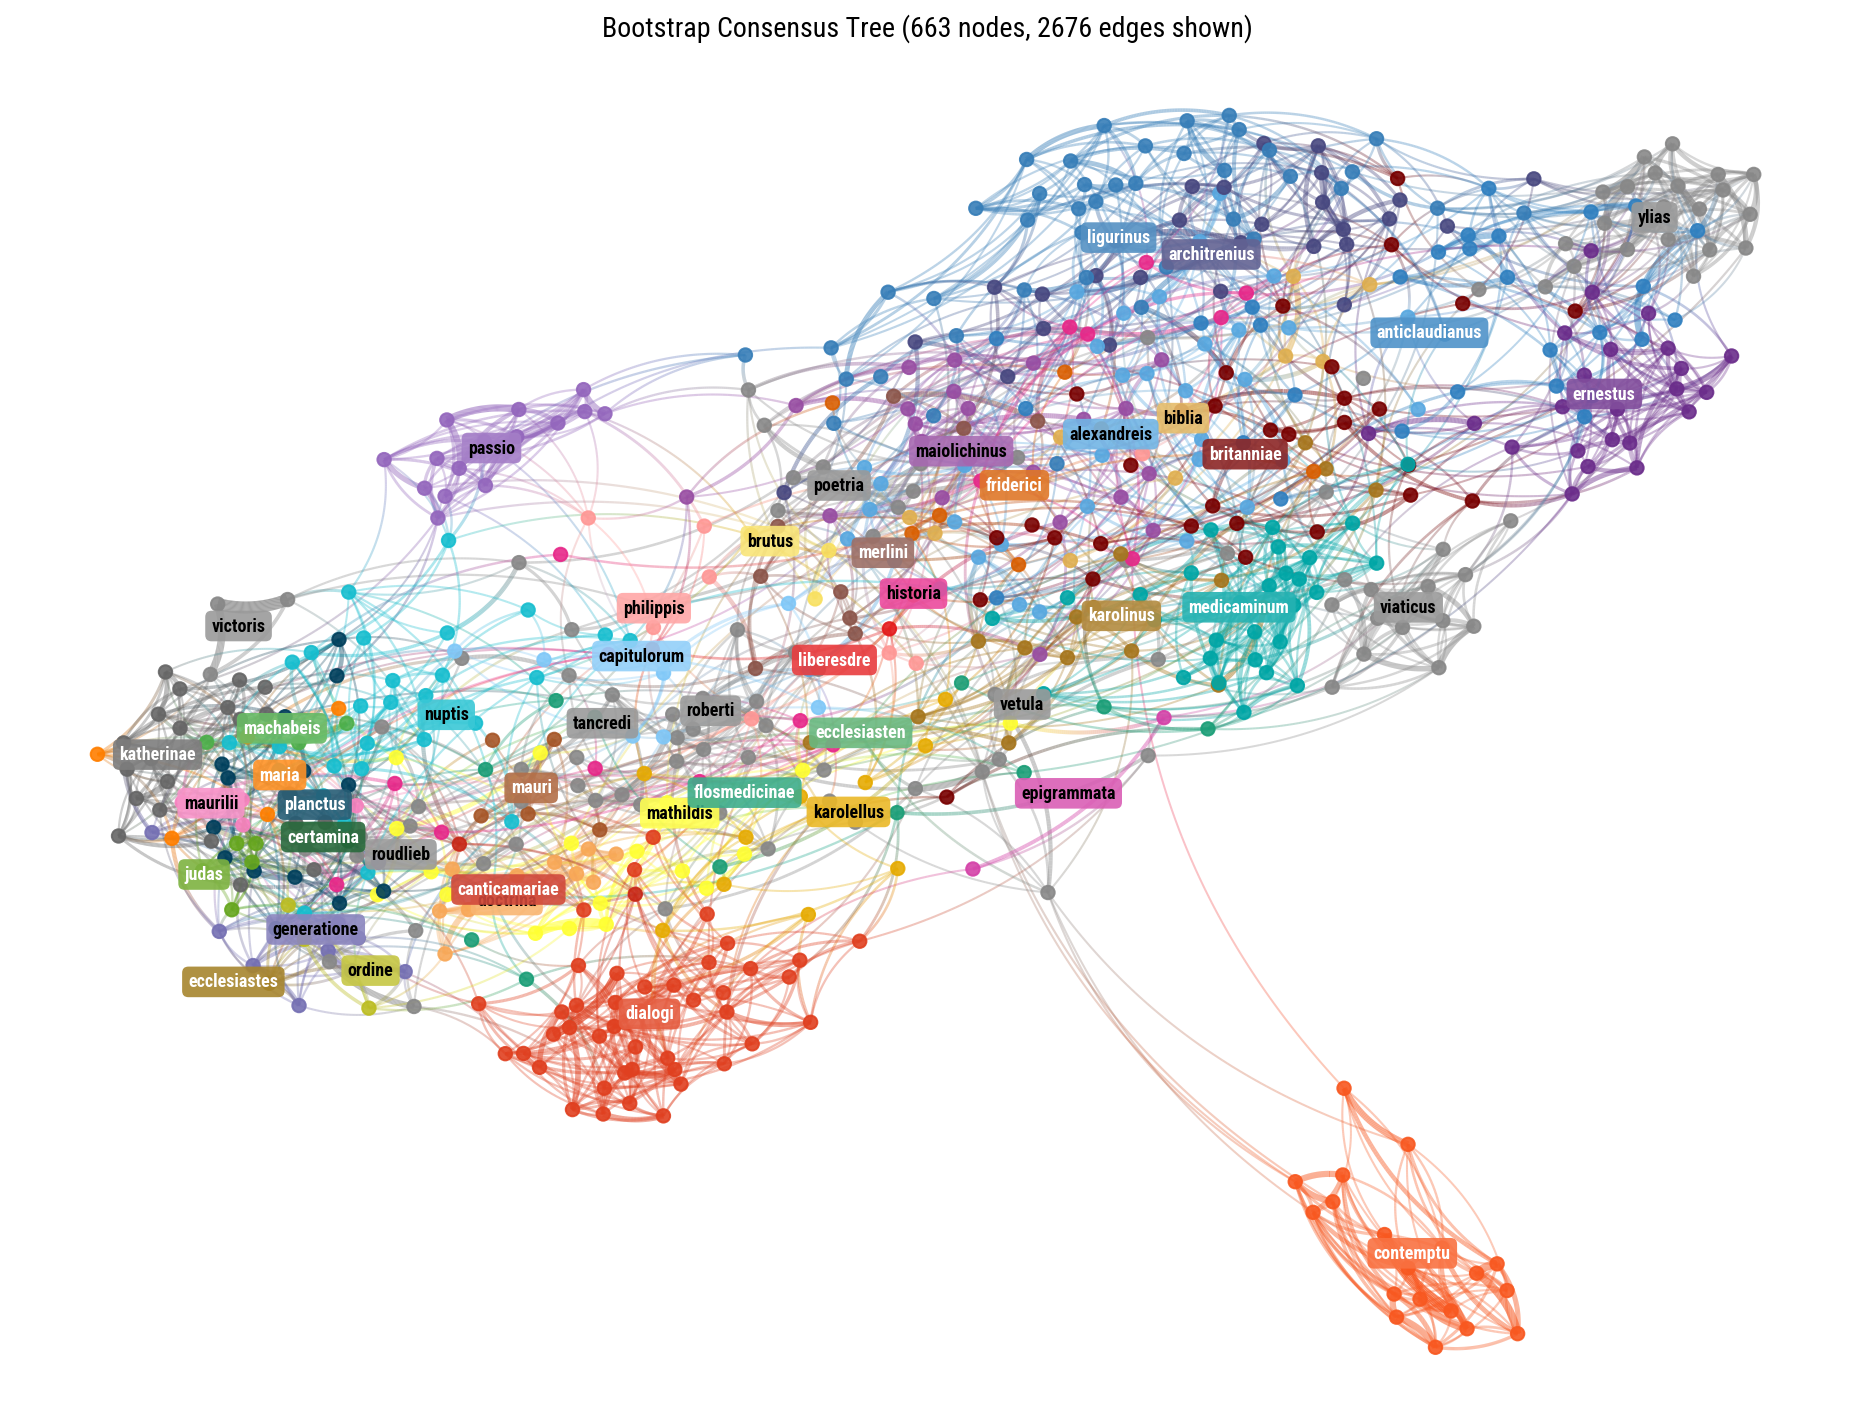

In [9]:
# 40-color palette
bct_palette = {
    w: c
    for w, c in zip(
        sorted(set(work_names)),
        [
            "#58A8E0", "#3080C0", "#484880",
            "#E0B050", "#780000", "#F8E060",
            "#C82818", "#80C8F8", "#024F19",
            "#F85820", "#E04020", "#F8A858",
            "#4EAC6A", "#987008", "#D442A8",
            "#6B2D8B", "#1B9E77", "#D95F02",
            "#7570B3", "#E7298A", "#66A61E",
            "#E6AB02", "#A6761D", "#666666",
            "#E41A1C", "#377EB8", "#4DAF4A",
            "#984EA3", "#FF7F00", "#FFFF33",
            "#A65628", "#F781BF", "#00A6A6",
            "#8C564B", "#17BECF", "#BCBD22",
            "#9467BD", "#FF9896", "#003F5C",
        ],
    )
}

fig, ax = plot_bct(
    graph_trim,
    work_names,
    y,
    palette=bct_palette,
    figsize=(14, 10),
    min_weight=130,
    layout_k=0.3,
    curvature=0.18,
    edge_width_range=(0.8, 6.0),
)
ax.legend().remove()
plt.savefig("bct_python.jpg", dpi=600, bbox_inches="tight")
plt.show()